In [ ]:
from pathlib import Path

import numpy as np

from skimage.io import imread

from matplotlib import pyplot as plt

In [2]:
model_dir = Path("/home/xgupke/Documents/projects/EmmaElinTrombocytes/pixel_classifier/runs/3")
images_dir = model_dir / "predictions"

In [3]:
labels_dict = {
    1: "granule",
    2: "tail",
    3: "spike"
}

In [4]:
crop_files = []
pred_files = []

for file in zip(images_dir.glob("pred_*"), images_dir.glob("crop_*")):
    pred_files.append(file[0])
    crop_files.append(file[1])    

In [5]:
pred_files

[PosixPath('/home/xgupke/Documents/projects/EmmaElinTrombocytes/pixel_classifier/runs/3/predictions/pred_40135_J5_new_x4300_-10um_0081_1.tif'),
 PosixPath('/home/xgupke/Documents/projects/EmmaElinTrombocytes/pixel_classifier/runs/3/predictions/pred_40135_G1_x4300_-10um_0033_1.tif'),
 PosixPath('/home/xgupke/Documents/projects/EmmaElinTrombocytes/pixel_classifier/runs/3/predictions/pred_40135_G1_x4300_-10um_0033_0.tif'),
 PosixPath('/home/xgupke/Documents/projects/EmmaElinTrombocytes/pixel_classifier/runs/3/predictions/pred_40135_E4_new_x4300_-10um_0001_0.tif'),
 PosixPath('/home/xgupke/Documents/projects/EmmaElinTrombocytes/pixel_classifier/runs/3/predictions/pred_40135_J5_new_x4300_-10um_0081_0.tif'),
 PosixPath('/home/xgupke/Documents/projects/EmmaElinTrombocytes/pixel_classifier/runs/3/predictions/pred_40135_E4_new_x4300_-10um_0044_0.tif')]

In [63]:
test_file = "0033"
# test_file = "0001"
pred_file = [f for f in pred_files if test_file in f.name][1]
crop_file = [f for f in crop_files if test_file in f.name][0]
pred_file, crop_file

(PosixPath('/home/xgupke/Documents/projects/EmmaElinTrombocytes/pixel_classifier/runs/3/predictions/pred_40135_G1_x4300_-10um_0033_0.tif'),
 PosixPath('/home/xgupke/Documents/projects/EmmaElinTrombocytes/pixel_classifier/runs/3/predictions/crop_40135_G1_x4300_-10um_0033_0.tif'))

In [64]:
img_pred = imread(pred_file)
img = imread(crop_file)

In [65]:
np.unique(img_pred)

array([  0,  85, 170, 255], dtype=uint8)

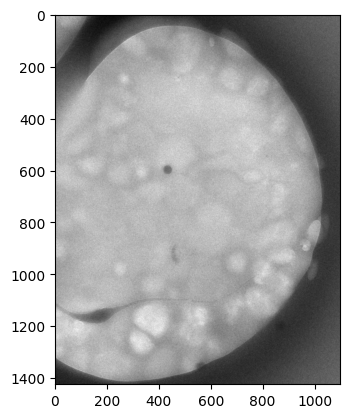

In [66]:
plt.imshow(img, cmap='grey')

Text(0.5, 0.98, '0044')

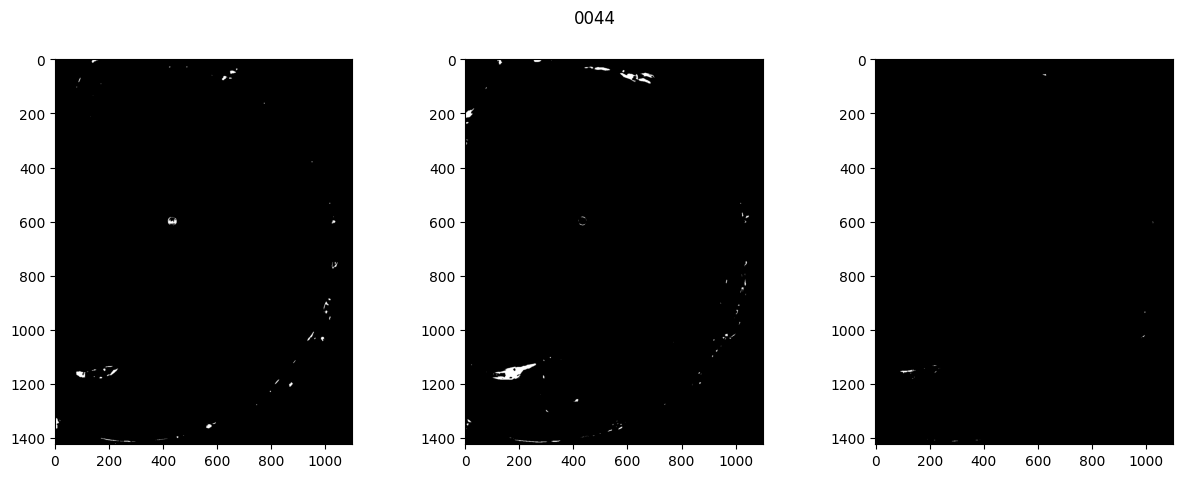

In [67]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for i,val in enumerate(sorted(np.unique(img_pred))[1:]):
    if val == 0:
        continue

    ax[i].imshow(img_pred == val, cmap="gray")

plt.suptitle("0044")

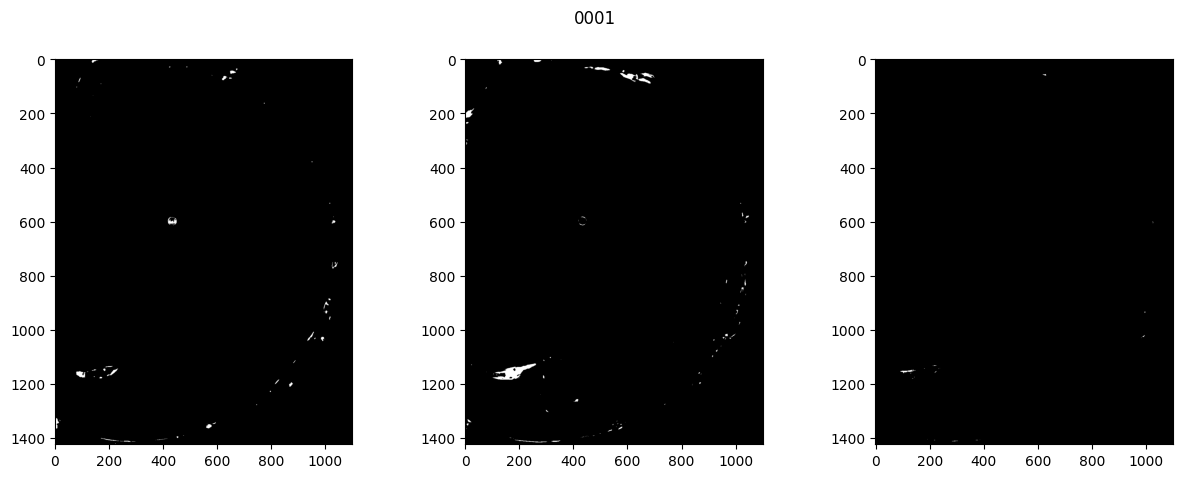

In [68]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for i,val in enumerate(sorted(np.unique(img_pred))[1:]):

    ax[i].imshow(img_pred == val, cmap="gray")

plt.suptitle("0001")
plt.show()

In [69]:
print("integer 2:", np.sum(img_pred == 2))
img_pred.dtype

integer 2: 0


dtype('uint8')

In [70]:
np.unique(img_pred)

array([  0,  85, 170, 255], dtype=uint8)

(1424, 1100)


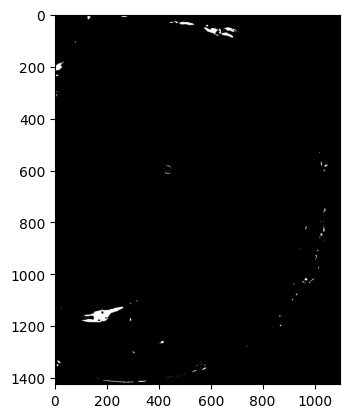

In [71]:
mask = img_pred == np.unique(img_pred)[2]
print(mask.shape)
plt.imshow(mask, cmap="gray")

In [72]:
mask.dtype

dtype('bool')

In [73]:
from scipy.ndimage import binary_fill_holes
from skimage.morphology import binary_closing, remove_small_objects, disk

# Classical processing: filling holes and closing

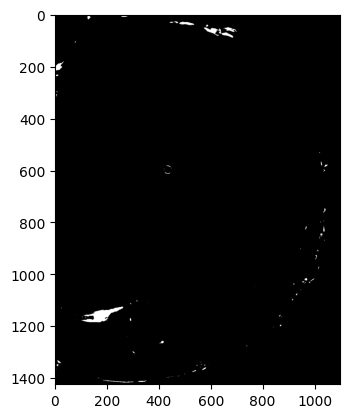

In [74]:
mask_filled = binary_fill_holes(mask, disk(3))
plt.imshow(mask_filled, cmap="gray")

/tmp/ipykernel_1486593/1723823240.py:1: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  mask_clean = binary_closing(mask_filled, footprint=disk(7))


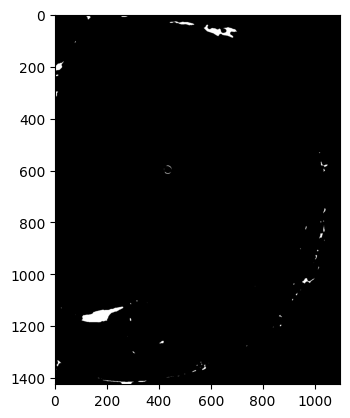

In [75]:
mask_clean = binary_closing(mask_filled, footprint=disk(7))
plt.imshow(mask_clean, cmap="gray")

True


/tmp/ipykernel_1486593/292543885.py:8: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  mask_ = binary_closing(mask_, footprint=disk(2*(3+i)))


True


/tmp/ipykernel_1486593/292543885.py:8: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  mask_ = binary_closing(mask_, footprint=disk(2*(3+i)))


False


...

/tmp/ipykernel_1486593/292543885.py:8: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  mask_ = binary_closing(mask_, footprint=disk(2*(3+i)))


False


/tmp/ipykernel_1486593/292543885.py:8: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  mask_ = binary_closing(mask_, footprint=disk(2*(3+i)))


False


/tmp/ipykernel_1486593/292543885.py:8: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  mask_ = binary_closing(mask_, footprint=disk(2*(3+i)))


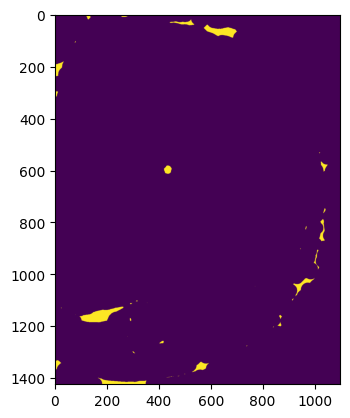

In [76]:
mask_ = mask.copy()
for i in range(10):
    mask_i = mask_.copy()
    mask_ = binary_fill_holes(mask_)

    has_holes = np.any(mask_ != mask_i)
    print(has_holes)
    mask_ = binary_closing(mask_, footprint=disk(2*(3+i)))

mask_ = binary_fill_holes(mask_)
plt.imshow(mask_)

/tmp/ipykernel_1486593/1839637148.py:1: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask_clean = remove_small_objects(


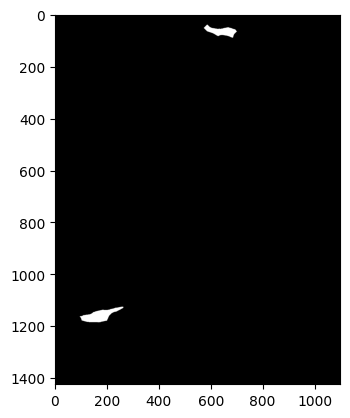

In [77]:
mask_clean = remove_small_objects(
    mask_.astype(bool),
    min_size=2500
)
plt.imshow(mask_clean, cmap="gray")

# Otsu plus classical

Otsu threshold: 2772


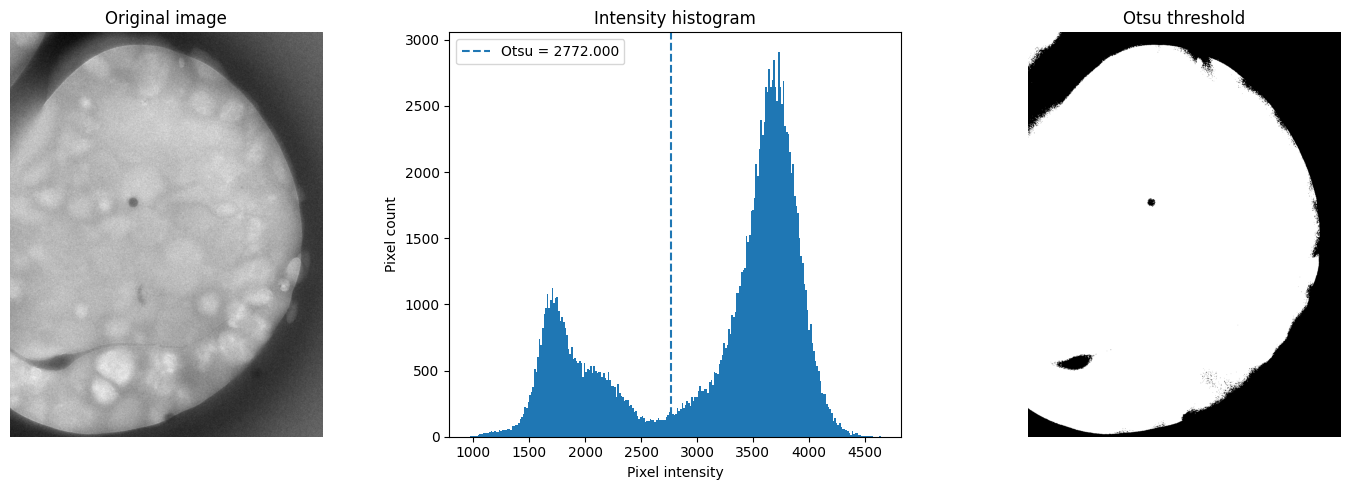

In [78]:
import matplotlib.pyplot as plt
from skimage.filters import threshold_otsu

# Calculate Otsu threshold
thresh = threshold_otsu(img)

# Create binary mask
mask_otsu = img > thresh

print("Otsu threshold:", thresh)

# Plot image, histogram, and thresholded mask
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(img, cmap="gray")
ax[0].set_title("Original image")
ax[0].axis("off")

ax[1].hist(img.ravel()[::10], bins=256)
ax[1].axvline(thresh, linestyle="--", label=f"Otsu = {thresh:.3f}")
ax[1].set_title("Intensity histogram")
ax[1].set_xlabel("Pixel intensity")
ax[1].set_ylabel("Pixel count")
ax[1].legend()

ax[2].imshow(mask_otsu, cmap="gray")
ax[2].set_title("Otsu threshold")
ax[2].axis("off")

plt.tight_layout()
plt.show()

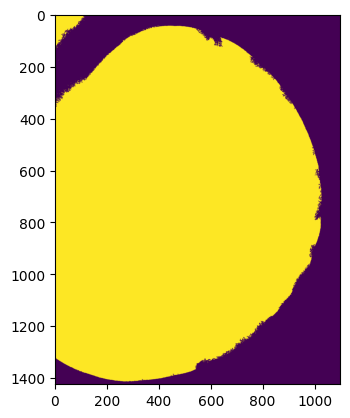

In [79]:
plt.imshow(binary_fill_holes(mask_otsu))

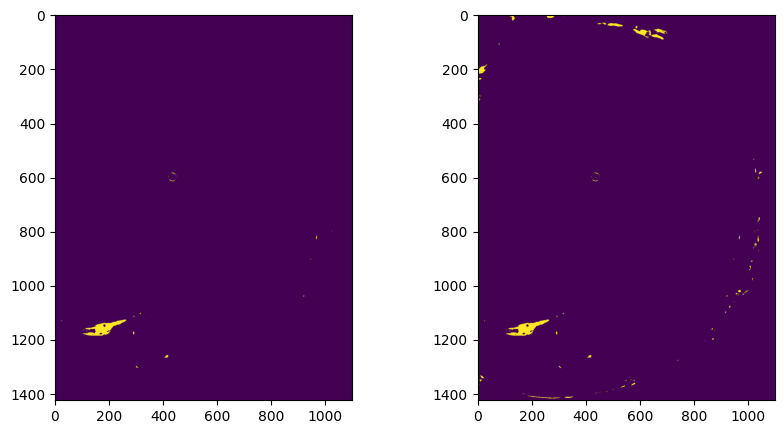

In [82]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(np.logical_and(binary_fill_holes(mask_otsu), img_pred==170))
ax[1].imshow(img_pred == 170)

Text(0.5, 1.0, 'Otsu mask')

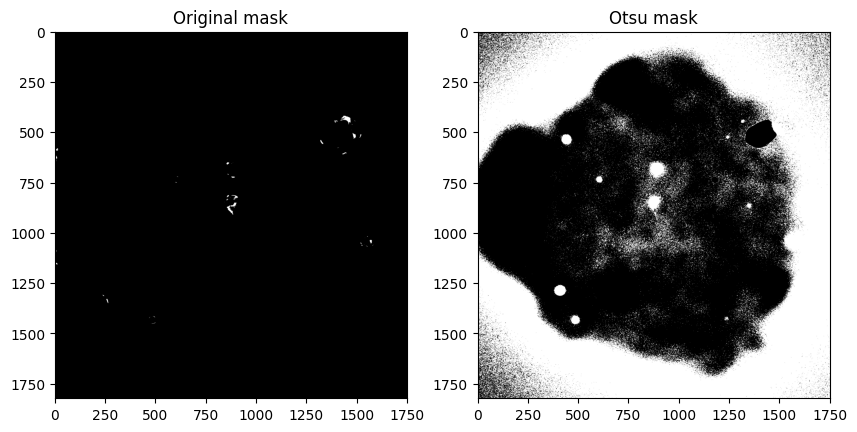

In [25]:
fig, ax = plt.subplots(1,2, figsize=(10, 5))
ax[0].imshow(mask, cmap="gray")
ax[0].set_title("Original mask")
ax[1].imshow(~mask_otsu, cmap="gray")
ax[1].set_title("Otsu mask")

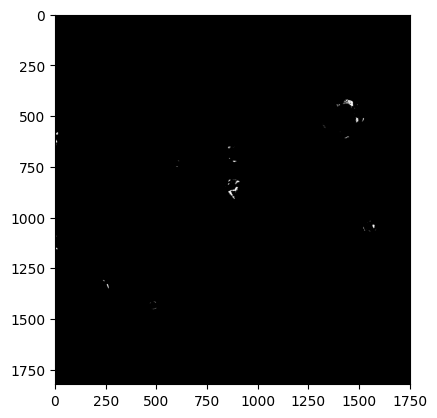

In [ ]:
plt.imshow(mask & ~mask_otsu, cmap="gray")

/tmp/ipykernel_971641/1890319211.py:3: FutureWarning: `binary_dilation` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.dilation` instead. Note the lack of mirroring for non-symmetric footprints (see docstring notes).
  mask_otsu_dilated = binary_dilation(mask_otsu, footprint=disk(21))
/tmp/ipykernel_971641/1890319211.py:4: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask_otsu_dilated = remove_small_objects(mask_otsu_dilated, min_size=1000)


Text(0.5, 1.0, 'Otsu mask')

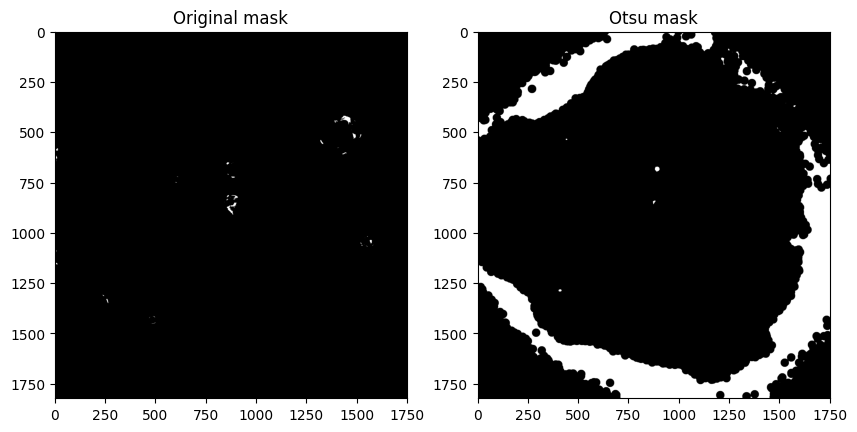

In [37]:
# Do a dilation on the otsu mask to make sure we get all the pixels that are part of the granules and tails
from skimage.morphology import binary_dilation
mask_otsu_dilated = binary_dilation(mask_otsu, footprint=disk(21))
mask_otsu_dilated = remove_small_objects(mask_otsu_dilated, min_size=1000)

fig, ax = plt.subplots(1,2, figsize=(10, 5))
ax[0].imshow(mask, cmap="gray")
ax[0].set_title("Original mask")
ax[1].imshow(~mask_otsu_dilated, cmap="gray")
ax[1].set_title("Otsu mask")

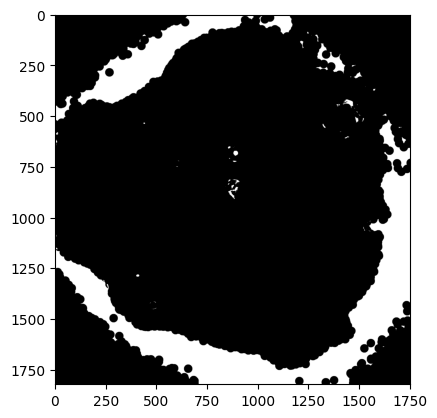

In [38]:
plt.imshow(mask | ~mask_otsu_dilated, cmap="gray")

In [ ]:
"""
The more you dilate the inverted otsu, the more granule pixels get removed
"""